## Analyzing a player's dismissals patterns, strengths and weaknesses

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import json

In [2]:
# Load JSON data
file_path = 'cricinfo_data_scrapping/virat_kohli_stats.json'
with open(file_path, 'r') as f:
    data = json.load(f)

# Extract the dismissals data and convert to DataFrame
dismissals_df = pd.DataFrame(data["dismissals"])

# Drop rows with 'Unknown' bowler type
dismissals_df = dismissals_df[dismissals_df["Bowler Type"] != "Unknown"]

# Display the first few rows to confirm structure
dismissals_df.head()


,Bowler Type,Span,Dis,bowled,caught-fielder,caught wk,stump,lbw,hit wicket,caught and bowled
0,Right arm Pace,2008 - 2024,110,12,56,35,0,7,0,0
1,Right arm Spin,2008 - 2024,46,9,16,6,3,8,1,3
2,Left arm Pace,2008 - 2024,34,5,18,9,0,2,0,0
3,Left arm Spin,2008 - 2024,24,5,11,1,2,2,0,3


In [3]:
# Display the summary of the DataFrame
print(dismissals_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 4 entries, 0 to 3
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Bowler Type        4 non-null      object
 1   Span               4 non-null      object
 2   Dis                4 non-null      int64 
 3   bowled             4 non-null      int64 
 4   caught-fielder     4 non-null      int64 
 5   caught wk          4 non-null      int64 
 6   stump              4 non-null      int64 
 7   lbw                4 non-null      int64 
 8   hit wicket         4 non-null      int64 
 9   caught and bowled  4 non-null      int64 
dtypes: int64(8), object(2)
memory usage: 352.0+ bytes
None


# Analysis of Dismissal Types for the player

The total number of dismissals for each bowler type

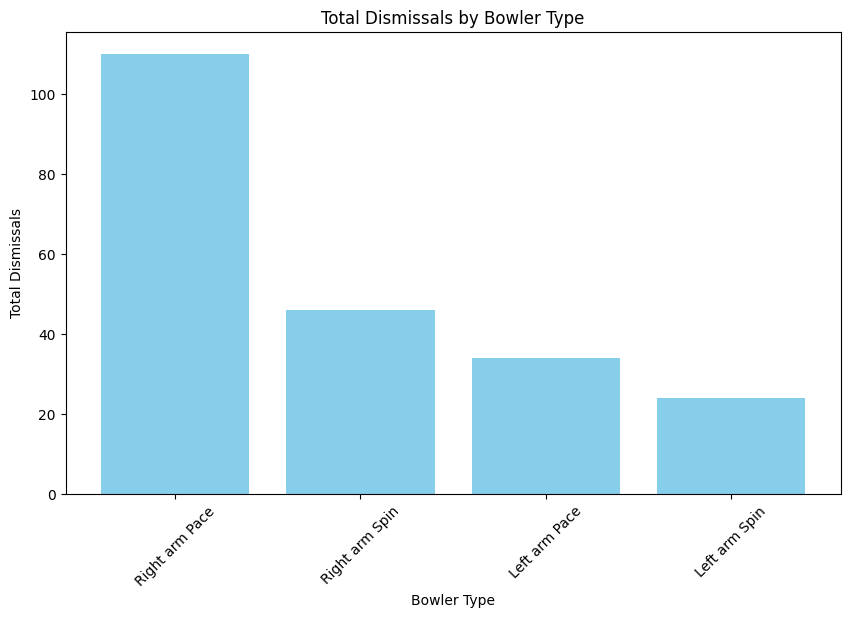

In [4]:
plt.figure(figsize=(10, 6))
plt.bar(dismissals_df["Bowler Type"], dismissals_df["Dis"], color='skyblue')
plt.xlabel("Bowler Type")
plt.ylabel("Total Dismissals")
plt.title("Total Dismissals by Bowler Type")
plt.xticks(rotation=45)
plt.show()


A pie chart visualization will display the different ways the player has been dismissed, showing the proportion of each dismissal type. This chart provides a clear and concise view of the frequency of each dismissal type

In [5]:
# Define dismissal types based on the data columns for types of dismissals
dismissal_types = ["bowled", "caught-fielder", "caught wk", "stump", "lbw", "hit wicket", "caught and bowled"]

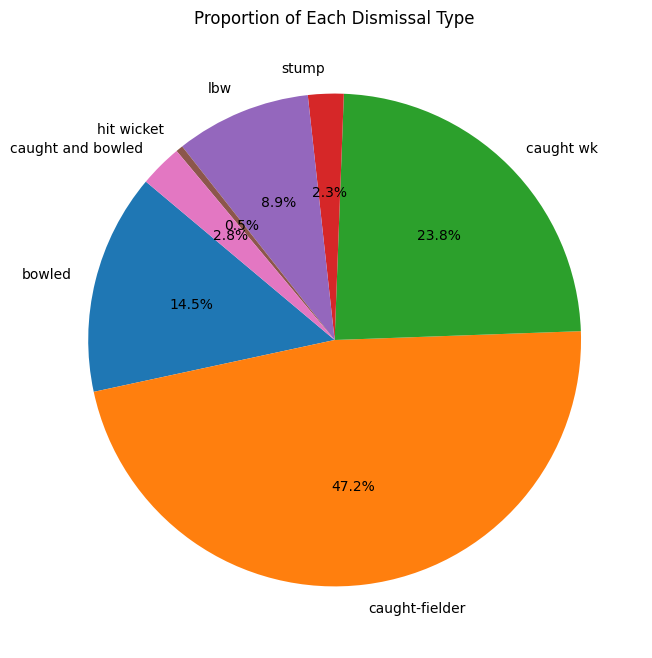

In [6]:
# Sum each dismissal type to get total counts across all bowler types
dismissal_totals = dismissals_df[dismissal_types].sum()

# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(dismissal_totals, labels=dismissal_totals.index, autopct='%1.1f%%', startangle=140)
plt.title("Proportion of Each Dismissal Type")
plt.show()


Dismissals of the player against diffrent bowler types

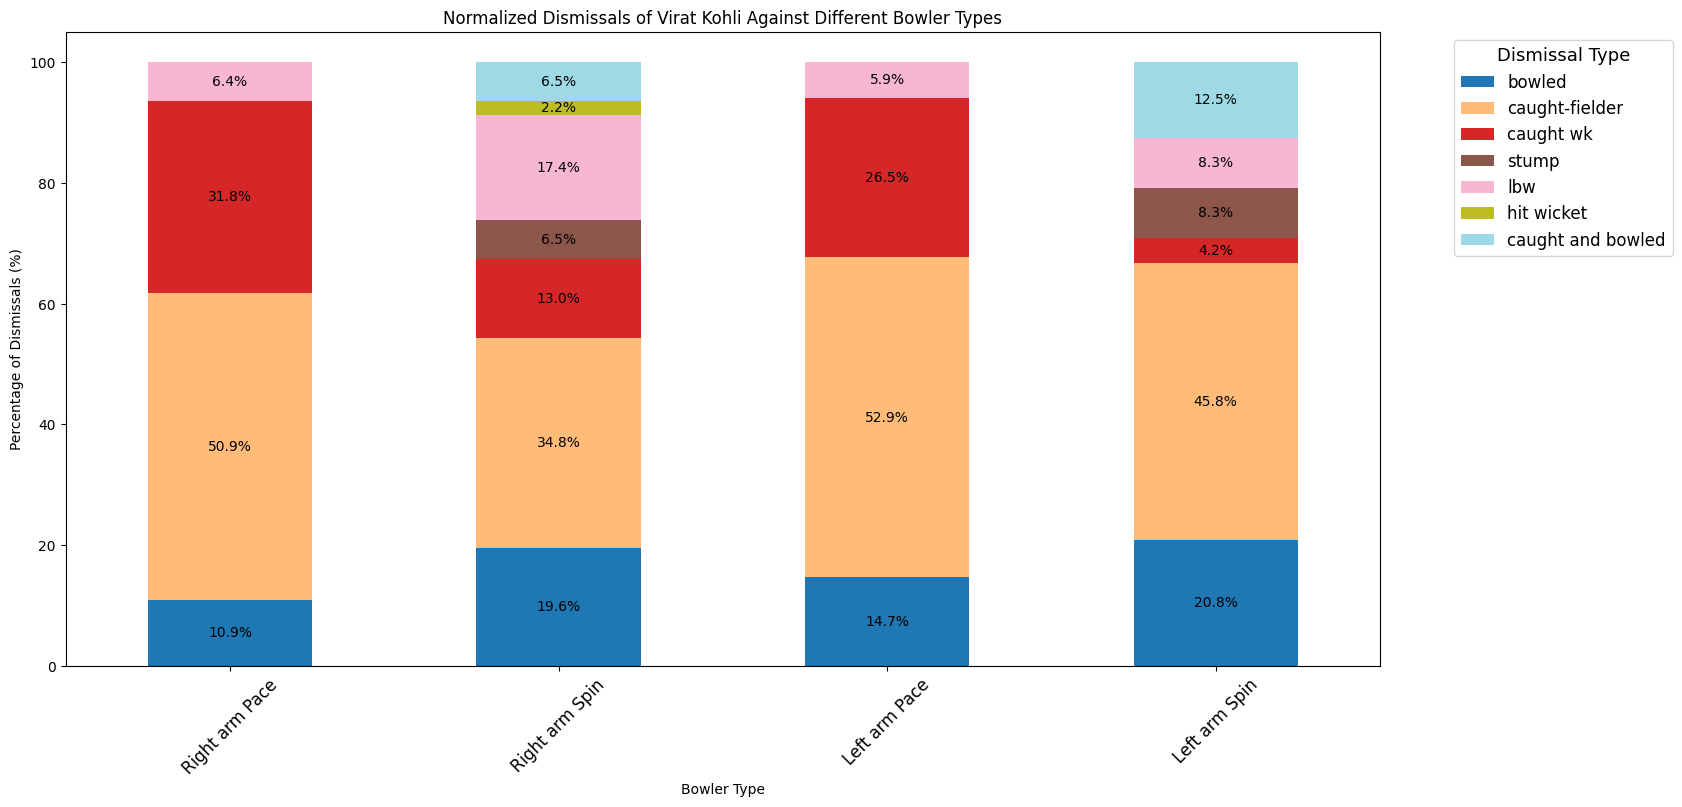

In [8]:
# Calculate total dismissals for each bowler type
dismissals_df['Total Dismissals'] = dismissals_df[dismissal_types].sum(axis=1)

# Normalize each dismissal type by the total dismissals for that bowler type
for dismissal_type in dismissal_types:
    dismissals_df[dismissal_type] = (dismissals_df[dismissal_type] / dismissals_df['Total Dismissals']) * 100

# Drop the total dismissals column as it's no longer needed
dismissals_df.drop(columns='Total Dismissals', inplace=True)

# Plot the normalized stacked bar plot
ax = dismissals_df.set_index('Bowler Type')[dismissal_types].plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')

# Add labels and title
plt.title(f'Normalized Dismissals of {data["player"]} Against Different Bowler Types')
plt.xlabel('Bowler Type')
plt.ylabel('Percentage of Dismissals (%)')
plt.xticks(rotation=45)
plt.tight_layout()

# Add percentage labels within the bars
for i in range(dismissals_df.shape[0]):
    bottom = 0
    for j, col in enumerate(dismissal_types):
        value = dismissals_df.iloc[i][col]
        if value > 0:
            ax.text(i, bottom + value / 2, f'{value:.1f}%', ha='center', va='center', color='black', fontsize=10)
        bottom += value

# Position the legend outside the plot area on the right
ax.legend(title='Dismissal Type', title_fontsize=13, fontsize=12, bbox_to_anchor=(1.05, 1), loc='upper left')
ax.tick_params(axis='x', labelsize=12)

# Show the plot
plt.show()


## Manual Insights

- We can see that Kohli has been dismissed by caught the most number of times. According to my observation Kohli has been caught behind or at slips when the ball is pitched at off stump and moving away from him.
- He tends to chip it to point and covers as well when he is trying to drive or cutt the ball.
- His running between the wickets is really good hence that ratio of runouts is less in the visualization.
- He is also very good in using his feet against spinner hence the stumps way of getting out is also less.

----------------------------------------------------------------------------------------------------------------

1. Left-Arm Pace

Kohli is cautious early on against left-arm pacers, focusing on getting singles. He often uses a slightly closed stance to guard against balls coming in but this can make him vulnerable to deliveries that move away.

Caught Behind: He sometimes pushes at balls outside off-stump, especially early in his innings, leading to edges to the slips or wicketkeeper.

LBW/Bowled: When the ball swings in, he can be trapped in front as he tries to flick across the line.

Left-arm pacers target his off-stump early when he’s trying to drive before settling.

He is confident in cover drives which is his favourite shot so early on when the ball is new, he gets caught in slip while driving because the swing factor comes in

2. Left-Arm Spin

Kohli uses his feet well, advancing to convert good-length deliveries into driveable balls. He also sweeps to control spin and manipulate the field.

Caught Close: On turning pitches, he can edge balls to slip or short leg when playing with hard hands.

LBW: If the ball drifts in and skids, he might miss it while trying to play across.

Kohli prefers to rotate strike but gets cautious when facing turn and bounce.

3. Right-Arm Pace

Kohli excels against right-arm pace, using a slightly open stance to drive straight and cover drives with a compact technique. He’s quick to adjust to bouncers, often playing hooks or uppercuts if the field allows.

Caught Behind: Pushing at outswingers early in his innings can lead to edges.

Caught: One observation is that, when the ball is pitched at short to good length he gets uncomfortable with the bounce early on. When he tries to hit it hard, it usually mistimes and gets caught within the range of the field circle

LBW/Bowled: Occasionally, he falls across when trying to flick, making him vulnerable to straight, full deliveries.

His eagerness to dominate pace can sometimes lead to early edges when the ball moves away from him.

4. Right-Arm Spin (Off-Spin and Leg-Spin)

Kohli uses his wrists to turn off-spin deliveries into the leg side. Against leg-spin, he uses quick footwork, often advancing to hit lofted shots or drive.

Caught: Mistimed lofted shots when he tries to dominate, especially against leg-spin.

Confident against spin, Kohli sometimes risks his wicket when he rushes to attack.

Even though he has played less balls from the left-arm-pace category, the dissmisaal rate is the most.

This means that he is most likely to get out from this category of bowler.

Left Arm Pacers (Over the Wicket):
- The Angle of the ball is from left to right. If the ball is new and swinging:
    1. Away: He ends up nicking which is usually carried to the keeper or slip cordon.
    2. In: The chance of LBW and getting bowled increases.

----------------------------------------------------------------------------------------------------------------

This shows us that the scoring rate of kohli is consistent against each type of bowler. This only shows us that in terms of runs scored, Kohli does not let any bowler dominate him as he scores consistently.

The visualization shows that the number of runs scored against the number of balls faced is approximately the same showing a strike rate of 100 

The deviation/variation of left arm spin from the other bowling types hints towards a slight weakness or a defensive approach against this type of bowling compared to the rest of the bowling types

----------------------------------------------------------------------------------------------------------------

- This is a better visualization to understand his career average against each bowling type
- Runs per dismissal is the lowest for left arm pace showing his direct weakness/ defensive approach against this category of bowling

- We can interestingly observe the average against left arm spin is quite higher which we would not have expected 
based on the previous graphs

- This could be due to a few reaons
- Sample Size of balls faced against left arm spinners is quite low 
- Spin friendly pitches only in Subcontinent ( Ban and Sri) 


----------------------------------------------------------------------------------------------------------------

Lowest Average Against Left-Arm Pace: His batting average against left-arm pace bowlers is the lowest.This indicates that Kohli is dismissed more frequently by left-arm pace bowlers compared to other types of bowlers, suggesting a relative vulnerability.

Comfort Against Right-Arm Spin: Kohli has fewer dismissals per runs scored against right-arm spin bowlers, indicating a higher batting average and showing that he is more comfortable playing against this type of bowling.